# ÇÖZÜM: K-En Yakın Komşu (KNN) ile Cinsiyet Tahmini

Bu çalışma kitabı, KNN ile cinsiyet tahmini öğrenci görevindeki eksik kısımların tamamlanmış **çözüm (cevap anahtarı)** versiyonudur.

## 1. Gerekli Kütüphanelerin Yüklenmesi ve Verinin Hazırlanması

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

# Veriyi yükleme
df = pd.read_excel('ayakkabi_numarasi.xlsx')

# Cinsiyet sütununu sayısal hedefe dönüştürme (Erkek: 1, Kadın: 0)
df['Cinsiyet_E'] = (df['Cinsiyet(E veya K)'] == 'E').astype(int)
df.head()

,Kilo(kg),Boy(metre),Yaş,Cinsiyet(E veya K),Ayakkabı Numarası,Cinsiyet_E
0,85,1.74,42,E,41,1
1,44,1.40,10,E,36,1
2,32,1.38,11,E,36,1
3,48,1.46,11,E,37,1
4,75,1.62,47,E,42,1


### ÇÖZÜM 1: X ve y Değişkenlerinin Ayrılması ve Eğitim/Test Bölünmesi

In [16]:
# X için bağımsız değişken sütun isimleri
feature_cols = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Ayakkabı Numarası']
X = df[feature_cols]

# y için hedef değişken sütun ismi
y = df['Cinsiyet_E']

# Veriyi %20 test olacak şekilde ayırma
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.16, random_state=42
)

print(f"Eğitim seti boyutu: {X_train.shape[0]}, Test seti boyutu: {X_test.shape[0]}")

Eğitim seti boyutu: 48, Test seti boyutu: 10


### ÇÖZÜM 2: Verilerin Ölçeklendirilmesi (StandardScaler)

In [17]:
scaler = StandardScaler()

# Eğitim verisini öğrenip dönüştürme
X_train_scaled = scaler.fit_transform(X_train)

# Test verisini eğitimdeki ölçeğe göre dönüştürme
X_test_scaled = scaler.transform(X_test)

### ÇÖZÜM 3: KNN Modelinin Kurulması ve Eğitilmesi

In [18]:
# Komşu sayısını (n_neighbors) 5 olarak ayarlama
model = KNeighborsClassifier(n_neighbors=5)

# Modeli ölçeklendirilmiş eğitim verisi ve y_train ile eğitme
model.fit(X_train_scaled, y_train)

print("KNN modeli başarıyla eğitildi!")

KNN modeli başarıyla eğitildi!


### ÇÖZÜM 4: Tahmin Yapma ve Modeli Değerlendirme

KNN Model Doğruluk Oranı (Accuracy): %90.00

              precision    recall  f1-score   support

   Kadın (0)       1.00      0.83      0.91         6
   Erkek (1)       0.80      1.00      0.89         4

    accuracy                           0.90        10
   macro avg       0.90      0.92      0.90        10
weighted avg       0.92      0.90      0.90        10



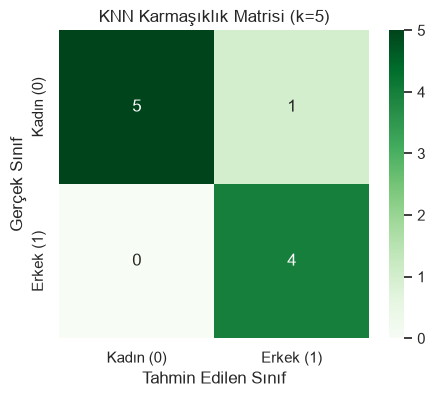

In [19]:
# Ölçeklendirilmiş test verisi ile tahmin üretme
y_pred = model.predict(X_test_scaled)

# Doğruluk (Accuracy) skorunu hesaplama
acc = accuracy_score(y_test, y_pred)
print(f"KNN Model Doğruluk Oranı (Accuracy): %{acc * 100:.2f}\n")

# Sınıflandırma Raporu
print(classification_report(y_test, y_pred, target_names=['Kadın (0)', 'Erkek (1)']))

# Karmaşıklık Matrisi Görselleştirmesi
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['Kadın (0)', 'Erkek (1)'], yticklabels=['Kadın (0)', 'Erkek (1)'])
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.title('KNN Karmaşıklık Matrisi (k=5)')
plt.show()

### ÇÖZÜM 5: Yeni Bireyler İçin Cinsiyet Tahmini Yapma

In [20]:
yeni_ornekler = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Ayakkabı Numarası': 43},
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Ayakkabı Numarası': 37}
])

# Yeni örnekleri scaler ile dönüştürme
yeni_ornekler_scaled = scaler.transform(yeni_ornekler)

# Model ile tahmin yapma
tahminler = model.predict(yeni_ornekler_scaled)

for i, row in yeni_ornekler.iterrows():
    etiket = 'Erkek (E)' if tahminler[i] == 1 else 'Kadın (K)'
    print(f"Birey {i+1} (Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg, Ayakkabı No: {row['Ayakkabı Numarası']}) -> Tahmin: {etiket}")

Birey 1 (Boy: 1.76m, Kilo: 78.0kg, Ayakkabı No: 43.0) -> Tahmin: Erkek (E)
Birey 2 (Boy: 1.63m, Kilo: 56.0kg, Ayakkabı No: 37.0) -> Tahmin: Kadın (K)
